# My work for the linear fit

In [5]:
import numpy as np
import scipy.stats
import scipy.special
import scipy.optimize
import scipy.integrate
import matplotlib.pyplot as plt


In [6]:
def plot_linear_data_set(x, y, y_err=None):
    """Plot linear data set and format the plot."""
    fig, ax = plt.subplots(1, 1)

    if y_err is not None:
        ax.errorbar(x, y, y_err, fmt=".", label="Data")
    else:
        ax.plot(x, y, marker=".", linestyle="none", label="Data")

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.legend(loc="upper left")

    return fig, ax

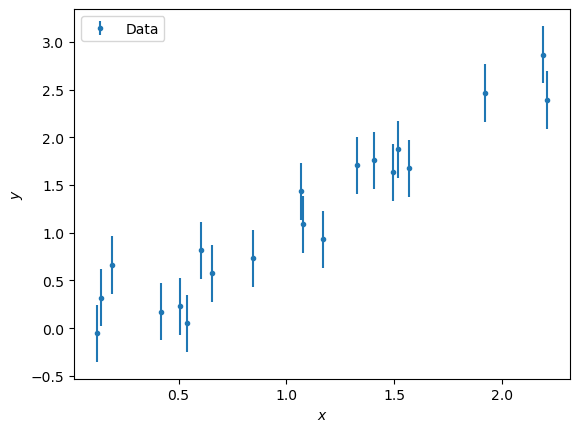

In [9]:
import numpy as np
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_0.txt", unpack=True)
# For now, all errors are the same
sigma_y = y_err[0]

_ = plot_linear_data_set(x, y, sigma_y)

In [11]:
def model(m,b,x):
    return (m*x+b)

In [24]:
def log_likelihood_probability(y, m, b, x, sigma_y):  # litterally the log of the gaussian e**(-(y_i-mu_i)**2/2sig*22)
    prediction = model(m,b,x)

    n = len(y)
    return (
         -0.5* np.sum((y-prediction)**2 / sigma_y**2)      #Exponent
        - n/2 * np.log(2*np.pi*sigma_y**2)  #Normalization
    )

    
    

In [14]:
#use priors once to check

m_prior = scipy.stats.norm(loc=1, scale=1)
b_prior = scipy.stats.norm(loc=0, scale=1.2)

def log_prior_probability(m, b):
    return m_prior.logpdf(m) + b_prior.logpdf(b)

Text(0.5, 1.0, 'logpdf: parabola')

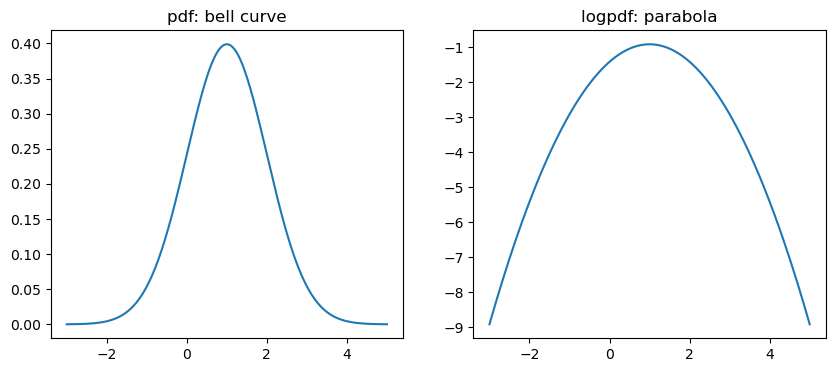

In [17]:
mm = np.linspace(-3, 5, 200)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(mm, m_prior.pdf(mm));    ax[0].set_title("pdf: bell curve")
ax[1].plot(mm, m_prior.logpdf(mm)); ax[1].set_title("logpdf: parabola")

In [15]:
def sample_prior(n_sample):
    """Sample n_sample times from the prior distribution."""
    return np.vstack((m_prior.rvs(n_sample), b_prior.rvs(n_sample))).T

# Fix the pseudo random number generator seed for reproducibility
np.random.seed(42)

# Evaluate the model at the prior sample parameters
prior_model_predictive = np.array(
    [model(*parameters, x) for parameters in sample_prior(n_sample=20)]
)

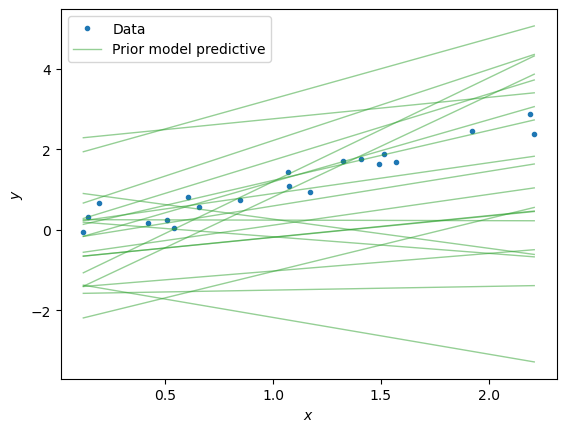

In [16]:
_, ax = plot_linear_data_set(x, y)

style = dict(c="C2", lw=1, alpha=0.5)
ax.plot(x, prior_model_predictive.T, **style)
ax.plot([], [], label="Prior model predictive", **style)
ax.legend();

In [26]:
# Ok we got priors well established and checked, now lets get posteriors:

def log_posterior_probability(m , b , x,sigma_y, y):
    return (log_likelihood_probability(y,m,b,x,sigma_y) + log_prior_probability(m,b)
           )

In [20]:
# MAP

In [27]:
# The scipy minimizer finds the minimum, so we need to take the 
# negative of the posterior. The scipy minimizer also passes an array 
# with the parameters, this wrapper splits this array into m and b.
def negative_log_posterior(theta, x, sigma_y, y):
    m, b = theta
    return -log_posterior_probability(m, b, x, sigma_y, y)

MAP_result = scipy.optimize.minimize(
    fun=negative_log_posterior,
    x0=(1, 0),
    args=(x, sigma_y, y)
)
m_MAP, b_MAP = MAP_result.x
m_true = 1.3
b_true = -0.2

print("MAP results")
print(f"m_MAP = {m_MAP:.3f}, b_MAP = {b_MAP:.3f}")
print(f"m_true = {m_true:.3f}, b_true = {b_true:.3f}")

MAP results
m_MAP = 1.251, b_MAP = -0.145
m_true = 1.300, b_true = -0.200


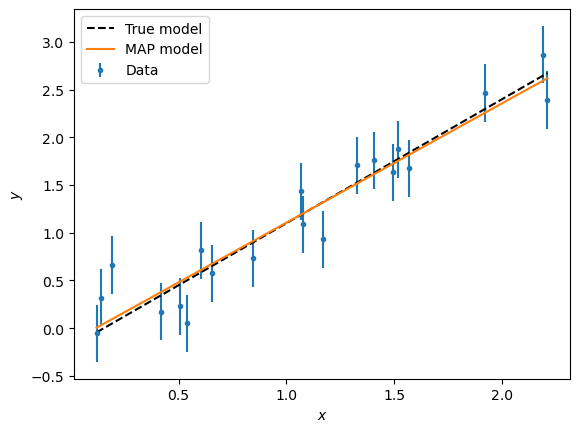

In [29]:
_, ax = plot_linear_data_set(x, y, sigma_y)

x_grid = np.linspace(0, 2.5, 100)
ax.plot(x, model(m_true, b_true, x), c="k", ls="--", label="True model")
ax.plot(x, model(m_MAP, b_MAP, x), c="C1", label="MAP model")
ax.legend();

In [30]:
import emcee

# emcee passes an array of values for the sampled parameters
# This wrapper just splits the array theta into m and b
def log_posterior_wrapper(theta, x, sigma_y, y):
    m, b = theta
    return log_posterior_probability(m, b, x, sigma_y, y)

# emcee requires some extra settings to run
n_param = 2       # Number of parameter we are sampling
n_walker = 10     # Number of walkers. This just needs to be 
                  # larger than 2*n_param + 1!
n_step = 5000     # How many steps each walker will take. The number
                  # of samples will be n_walker*n_step

# The starting point for each walker
theta_init = np.array([0.5, 0.5]) \
    + 0.1*np.random.normal(size=(n_walker, n_param))

sampler = emcee.EnsembleSampler(
    nwalkers=n_walker, ndim=n_param,
    log_prob_fn=log_posterior_wrapper,
    args=(x, sigma_y, y)
)
state = sampler.run_mcmc(theta_init, nsteps=n_step)

In [31]:
# The samples will be correlated, this checks how correlated they are
# We will discuss this once we come to MCMC methods
print("Auto-correlation time:")
for name, value in zip(["m", "b", "f"], sampler.get_autocorr_time()):
    print(f"{name} = {value:.1f}")

# We need to discard the beginning of the chain (a few auto-correlation times)
# to get rid of the initial conditions
chain = sampler.get_chain(discard=300, thin=10, flat=True)

Auto-correlation time:
m = 39.4
b = 46.8


In [32]:
print("Posterior results (mean±std)")
print(f"m = {np.mean(chain[:,0]):.2f}±{np.std(chain[:,0]):.2f}")
print(f"b = {np.mean(chain[:,1]):.2f}±{np.std(chain[:,1]):.2f}")

Posterior results (mean±std)
m = 1.25±0.10
b = -0.14±0.13


In [33]:
import corner

fig = plt.figure()
fig = corner.corner(
    chain,
    bins=40,
    labels=["m", "b"],
    color="C0",
    truths=[m_true, b_true],
    truth_color="C1",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
    quantiles=[0.025, 0.16, 0.84, 0.975],
    fig=fig
);
fig.get_axes()[0].plot([], [], c="C0", label="Samples from the posterior")
fig.get_axes()[0].plot([], [], c="C1", label="True parameters")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))
plt.close()

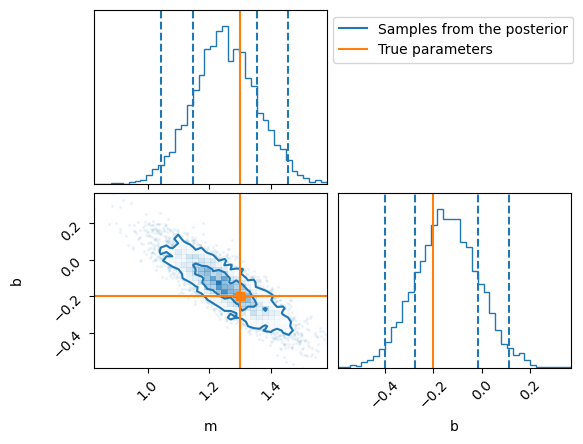

In [34]:
fig

In [35]:
# Choose a small subsample of the chain for plotting purposes
chain_samples = chain[np.random.choice(chain.shape[0], size=200)]
# Evaluate the model at the sample parameters
model_predictive = np.array(
    [model(*sample, x) for sample in chain_samples]
)
model_quantiles = np.quantile(
    model_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
)

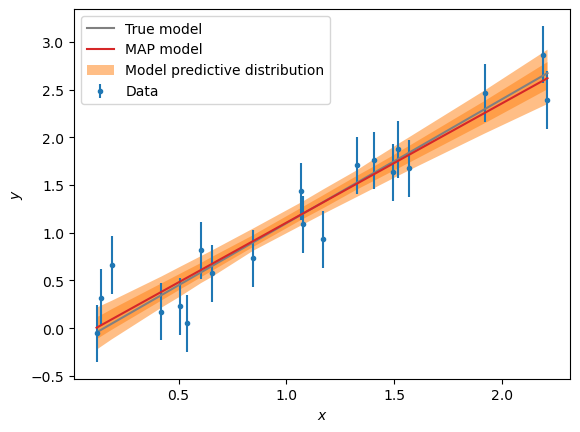

In [36]:
_, ax = plot_linear_data_set(x, y, sigma_y)
ax.plot(x, model(m_true, b_true, x), c="grey", label="True model")

ax.plot(x, model(m_MAP, b_MAP, x), c="C3", label="MAP model")
ax.fill_between(x, model_quantiles[0], model_quantiles[-1], alpha=0.5, facecolor="C1",
                label="Model predictive distribution")
ax.fill_between(x, model_quantiles[1], model_quantiles[-2], alpha=0.5, facecolor="C1")
ax.legend();

In [37]:
# Because we have a Gaussian likelihood with variance \sigma_y^2, we can sample
# from the posterior predictive distribution by adding Gaussian noise with
# variance \sigma_y^2 to the model prediction samples
posterior_predictive = \
    model_predictive + sigma_y*np.random.normal(size=model_predictive.shape)

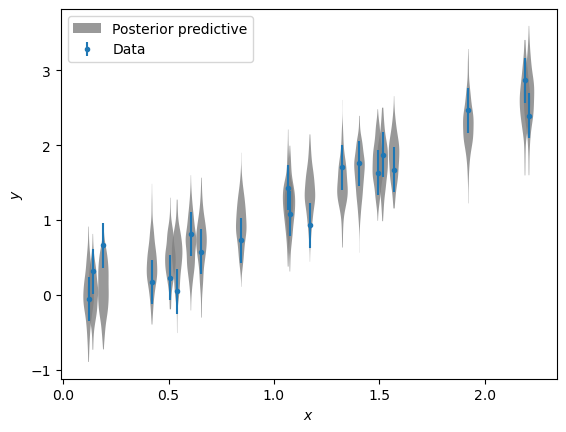

In [38]:
_, ax = plot_linear_data_set(x, y, sigma_y)

violin_plots = ax.violinplot(
    dataset=posterior_predictive,
    positions=x, widths=0.05,
    vert=True, showmeans=False, showextrema=False,
)
for body in violin_plots["bodies"]:
    body.set(color="grey", alpha=0.8, edgecolor=None)
body.set(label="Posterior predictive")

ax.legend();